# Count data: Poisson, negative binomial and Gamma GLMMs

Generalized linear mixed models for counts and for positive continuous responses:

* the **grouseticks** data (Elston et al. 2001): ticks on red grouse chicks, with nested random
  effects for chick (`INDEX`), brood (`BROOD`) and location (`LOCATION`);
* **overdispersion** diagnostics: the Pearson χ² statistic over its residual degrees of freedom;
* an **observation-level random effect** (OLRE) as a remedy for overdispersion;
* the **negative binomial** GLMM with `glmer.nb()`, its dispersion parameter θ
  (`getME(m, "glmer.nb.theta")`), and the simulated example of `?glmer.nb`;
* a Poisson model with an **offset** (exposure), and its negative binomial counterpart;
* comparing Poisson and negative binomial fits with AIC and likelihood-ratio tests (`anova`);
* a **Gamma** GLMM with a log link — a family with a free dispersion parameter.

## Source

* lme4 help pages: [`?grouseticks`](https://github.com/lme4/lme4/blob/master/man/grouseticks.Rd),
  [`?glmer.nb`](https://github.com/lme4/lme4/blob/master/man/glmer.nb.Rd),
  [`?glmer`](https://github.com/lme4/lme4/blob/master/man/glmer.Rd)
  (local copies in `upstream/lme4/man/`).
* lme4 tests: `upstream/lme4/tests/elston.R` (the grouseticks deviance check),
  `nbinom.R` (`glmer.nb`), `glmmExt.R` (Gamma and other families/links).
* Elston, D. A., Moss, R., Boulinier, T., Arrowsmith, C. and Lambin, X. (2001). Analysis of
  aggregation, a worked example: numbers of ticks on red grouse chicks. *Parasitology* 122, 563–569.
* Ben Bolker's [GLMM FAQ](https://bbolker.github.io/mixedmodels-misc/glmmFAQ.html)
  (overdispersion, observation-level random effects).

The R code reproduced here (the full script is `examples/r/04_count_data_poisson_negative_binomial.R`):

```r
library(lme4)
## ?grouseticks
form <- TICKS ~ YEAR + HEIGHT + (1|BROOD) + (1|INDEX) + (1|LOCATION)
(full_mod1 <- glmer(form, family = "poisson", data = grouseticks))
## with HEIGHT centred and scaled; with and without the OLRE (1|INDEX)
m1 <- glmer(TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|INDEX) + (1|LOCATION),
            family = poisson, data = grouseticks)
m0 <- glmer(TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|LOCATION),
            family = poisson, data = grouseticks)
sum(residuals(m0, type = "pearson")^2) / df.residual(m0)   # overdispersion
nb0 <- glmer.nb(TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|LOCATION), data = grouseticks)
getME(nb0, "glmer.nb.theta")
AIC(m0, m1, nb0); anova(m0, m1); anova(m0, nb0)

## ?glmer.nb
set.seed(101)
dd <- expand.grid(f1 = factor(1:3), f2 = LETTERS[1:2], g = 1:9, rep = 1:15,
                  KEEP.OUT.ATTRS = FALSE)
mu <- 5*(-4 + with(dd, as.integer(f1) + 4*as.numeric(f2)))
dd$y <- rnbinom(nrow(dd), mu = mu, size = 0.5)
m.glm <- MASS::glm.nb(y ~ f1*f2, data = dd)
m.nb <- glmer.nb(y ~ f1*f2 + (1|g), data = dd)
getME(m.nb, "glmer.nb.theta")

## offset: ticks per brood with the number of chicks as exposure
mo  <- glmer(TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1|LOCATION),
             family = poisson, data = agg)
nbo <- glmer.nb(TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1|LOCATION), data = agg)
predict(mo, newdata = nd, re.form = NA, type = "response")

## Gamma GLMM, log link
gm <- glmer(Reaction ~ Days + (Days | Subject), data = sleepstudy, family = Gamma(link = "log"))
```

## Setup

`check_fit()` compares a fit with its R reference: log-likelihood, deviance, AIC and BIC with
`rtol = 1e-8`; fixed effects and θ with `rtol = 1e-6` unless the likelihood surface is flat
(explained where it happens); standard errors with `rtol = 1e-4`, because the covariance of the
fixed effects of a GLMM is the inverse of a finite-difference Hessian of the deviance, which
amplifies differences in the last digits of the optimum. The Pearson χ² statistic depends on the
conditional modes and is compared with the same tolerance as the estimates.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.testing import assert_allclose, assert_equal
from scipy.stats import chi2

import lme4
from lme4 import Gamma, glmer, glmer_nb, load_dataset, poisson

with open("reference/04_count_data_poisson_negative_binomial.json") as fh:
    ref = json.load(fh)
print(ref["R_version"], "| lme4", ref["lme4_version"], "| Python lme4", lme4.__version__)


def pearson_chisq(m):
    return float(np.sum(np.asarray(m.residuals(type="pearson")) ** 2))


def as_list(x):
    return x if isinstance(x, list) else [x]


def check_fit(m, r, est_rtol=1e-6, ll_rtol=1e-8, se_rtol=1e-4, theta_atol=0.0):
    # Compare a fit with an R reference entry (see examples/r/04_*.R).
    assert_allclose(m.logLik().value, r["logLik"], rtol=ll_rtol)
    assert_equal(m.logLik().df, r["df"])
    assert_allclose(m.deviance(), r["deviance"], rtol=max(ll_rtol, est_rtol))
    assert_allclose(m.AIC(), r["AIC"], rtol=ll_rtol)
    assert_allclose(m.BIC(), r["BIC"], rtol=ll_rtol)
    assert_equal(m.df_residual(), r["df_residual"])
    assert_equal(list(m.fixef().index), list(r["fixef"]))
    assert_allclose(m.fixef().values, list(r["fixef"].values()), rtol=est_rtol)
    assert_allclose(np.asarray(m.getME("theta")), as_list(r["theta"]), rtol=est_rtol, atol=theta_atol)
    assert_allclose(m.sigma(), r["sigma"], rtol=est_rtol)
    assert_allclose(np.sqrt(np.diag(np.asarray(m.vcov()))), as_list(r["se"]), rtol=max(se_rtol, est_rtol))
    assert_allclose(pearson_chisq(m), r["pearson_chisq"], rtol=max(est_rtol, 1e-6))

R version 4.6.2 (2026-10-29) | lme4 2.1.0 | Python lme4 2.1.0a2


## 1. grouseticks

`grouseticks` has one row per chick: `TICKS` (number of ticks on its head), `BROOD`, `LOCATION`,
`YEAR` (95, 96, 97) and `HEIGHT` (altitude in metres). `INDEX` identifies the chick, so
`(1|INDEX)` is an observation-level random effect. `grouseticks_agg` holds brood means and
variances (Figure 1 of Elston et al.): the within-brood variance grows much faster than the
mean — the counts are overdispersed relative to the Poisson (variance = mean, dashed line).

In [2]:
grouseticks = load_dataset("grouseticks")
grouseticks_agg = load_dataset("grouseticks_agg")
print(grouseticks.shape)
grouseticks.head()

(403, 7)


,INDEX,TICKS,BROOD,HEIGHT,YEAR,LOCATION,cHEIGHT
0,1,0.0,501,465.0,95,32,2.759305
1,2,0.0,501,465.0,95,32,2.759305
2,3,0.0,502,472.0,95,36,9.759305
3,4,0.0,503,475.0,95,37,12.759305
4,5,0.0,503,475.0,95,37,12.759305


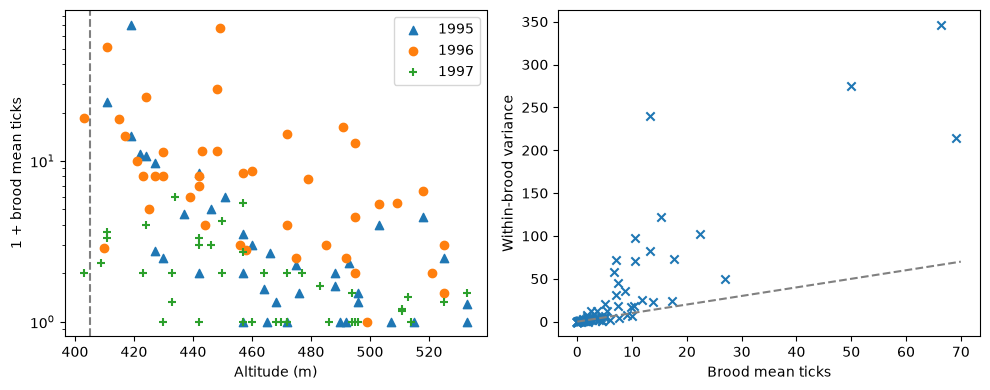

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for (yr, d), mk in zip(grouseticks_agg.groupby("YEAR", observed=True), ["^", "o", "+"]):
    ax[0].scatter(d["HEIGHT"], 1 + d["meanTICKS"], marker=mk, label=f"19{yr}")
ax[0].set_yscale("log"); ax[0].axvline(405, ls="--", c="grey")
ax[0].set_xlabel("Altitude (m)"); ax[0].set_ylabel("1 + brood mean ticks"); ax[0].legend()
ax[1].scatter(grouseticks_agg["meanTICKS"], grouseticks_agg["varTICKS"], marker="x")
ax[1].plot([0, 70], [0, 70], "--", c="grey")
ax[1].set_xlabel("Brood mean ticks"); ax[1].set_ylabel("Within-brood variance")
plt.tight_layout()

### The model of `?grouseticks`, on the original scale of HEIGHT

`tests/elston.R` checks the Laplace deviance at stored parameter values (θ, β) — a check of the
deviance function itself, independent of the optimizer:

In [4]:
form = "TICKS ~ YEAR + HEIGHT + (1|BROOD) + (1|INDEX) + (1|LOCATION)"
devfun = glmer(form, family=poisson, data=grouseticks, devFunOnly=True)
elston_pars = np.array([0.541509425632023, 0.750034415832756, 0.528723159081737,
                        11.3559080756861, 1.1804105508475, -0.978704335712111,
                        -0.0237607330254979])
print(devfun(elston_pars))

1780.5426603721335


Fitting this model gives the same convergence warnings as in R: `HEIGHT` ranges from 403 to
533 m, so its coefficient is about 1000 times smaller than the intercept, and the Hessian is
badly scaled ("Rescale variables?").

In [5]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    full_mod1 = glmer(form, family=poisson, data=grouseticks)
for x in w:
    print("Warning:", x.message)
print(full_mod1)

  See ?lme4::convergence and ?lme4::troubleshooting.
 - Rescale variables?;Model is nearly unidentifiable: large eigenvalue ratio
 - Rescale variables?
Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: TICKS ~ YEAR + HEIGHT + (1 | BROOD) + (1 | INDEX) + (1 | LOCATION)
   Data: grouseticks
      AIC       BIC    logLik -2*log(L)  df.resid 
1794.5427 1822.5352 -890.2713 1780.5427       396 
Random effects:
 Groups   Name        Std.Dev.
 INDEX    (Intercept) 0.5415  
 BROOD    (Intercept) 0.7500  
 LOCATION (Intercept) 0.5287  
Number of obs: 403, groups:  INDEX, 403; BROOD, 118; LOCATION, 63
Fixed Effects:
(Intercept)       YEAR96       YEAR97       HEIGHT  
   11.35577      1.18041     -0.97870     -0.02376  
optimizer (Nelder_Mead) convergence code: 0 (OK) ; 0 optimizer warnings; 3 lme4 warnings 


### Scaled HEIGHT

Following the warning, `scale(HEIGHT)` centres and scales altitude. The fit converges
cleanly; the log-likelihood is the same (the model is a reparametrization).

In [6]:
m1 = glmer("TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|INDEX) + (1|LOCATION)",
           family=poisson, data=grouseticks)
print(m1.summary())

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: TICKS ~ YEAR + scale(HEIGHT) + (1 | BROOD) + (1 | INDEX) + (1 | LOCATION)
   Data: grouseticks

      AIC       BIC    logLik -2*log(L)  df.resid 
   1794.5    1822.5    -890.3    1780.5       396 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.6123 -0.5536 -0.1486  0.2850  2.4430 

Random effects:
 Groups   Name        Variance Std.Dev.
 INDEX    (Intercept) 0.2932   0.5415  
 BROOD    (Intercept) 0.5625   0.7500  
 LOCATION (Intercept) 0.2796   0.5287  
Number of obs: 403, groups:  INDEX, 403; BROOD, 118; LOCATION, 63

Fixed effects:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept)     0.3728     0.1964   1.898 0.057668 .  
YEAR96          1.1804     0.2381   4.957 7.15e-07 ***
YEAR97         -0.9787     0.2628  -3.724 0.000196 ***
scale(HEIGHT)  -0.8543     0.1236  -6.910 4.84e-12 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**

## 2. Overdispersion and the observation-level random effect

Without `(1|INDEX)`, a Poisson GLMM assumes that, conditional on the brood and location effects,
the counts have variance equal to their mean. A simple check (GLMM FAQ) is the sum of squared
Pearson residuals divided by the residual degrees of freedom, which should be close to 1; under
the model it is approximately χ² distributed with `df.residual` degrees of freedom.

In [7]:
m0 = glmer("TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|LOCATION)",
           family=poisson, data=grouseticks)


def overdisp(m):
    chisq, rdf = pearson_chisq(m), m.df_residual()
    return pd.Series({"chisq": chisq, "ratio": chisq / rdf, "rdf": rdf, "p": chi2.sf(chisq, rdf)})


pd.DataFrame({"m0 (no OLRE)": overdisp(m0), "m1 (OLRE)": overdisp(m1)}).T

,chisq,ratio,rdf,p
m0 (no OLRE),691.136443,1.740898,397.0,3.147362e-18
m1 (OLRE),163.209723,0.412146,396.0,1.000000e+00


The ratio is about 1.74 for `m0` (p ≈ 1e-18): strong overdispersion. With the OLRE the ratio
drops to about 0.41 — Pearson residuals of a model with an observation-level effect are computed
at the conditional modes, which absorb part of the extra variation, so a ratio below 1 is
expected and not a sign of underdispersion.

The variance of the OLRE is clearly non-zero; the likelihood-ratio test of `anova(m0, m1)` is
conservative here since the null value σ²_INDEX = 0 is on the boundary (the p-value could be
halved):

In [8]:
a01 = m0.anova(m1)
a01

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
MODEL1,6,1987.876308,2011.869927,-987.938154,1975.876308,NaN,NaN,NaN
MODEL2,7,1794.542660,1822.535216,-890.271330,1780.542660,195.333647,1.0,2.178679e-44


## 3. Negative binomial GLMM: `glmer.nb()`

The negative binomial with variance μ + μ²/θ is the other standard remedy. `glmer_nb()` alternates
between fitting a GLMM with θ fixed and optimizing θ (as in R, an initial value comes from a Poisson
fit and `MASS::theta.ml`). The estimate of θ is returned by `getME(m, "glmer.nb.theta")`.

In [9]:
nb0 = glmer_nb("TICKS ~ YEAR + scale(HEIGHT) + (1|BROOD) + (1|LOCATION)", data=grouseticks)
print(nb0.summary())
print("theta =", nb0.getME("glmer.nb.theta"))

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Negative Binomial(3.3034)  ( log )
Formula: TICKS ~ YEAR + scale(HEIGHT) + (1 | BROOD) + (1 | LOCATION)
   Data: grouseticks

      AIC       BIC    logLik -2*log(L)  df.resid 
   1791.7    1819.7    -888.8    1777.7       396 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.4798 -0.6080 -0.3085  0.4916  3.4182 

Random effects:
 Groups   Name        Variance Std.Dev.
 BROOD    (Intercept) 0.5012   0.7079  
 LOCATION (Intercept) 0.3341   0.5780  
Number of obs: 403, groups:  BROOD, 118; LOCATION, 63

Fixed effects:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept)     0.4885     0.1939   2.519 0.011764 *  
YEAR96          1.1627     0.2326   4.999 5.75e-07 ***
YEAR97         -0.9796     0.2566  -3.818 0.000134 ***
scale(HEIGHT)  -0.8479     0.1250  -6.783 1.18e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fi

### Poisson vs negative binomial

The three models of the same response can be compared with AIC. The negative binomial and the
OLRE Poisson model both have 7 parameters, and their AICs are close (the NB is slightly better);
both are much better than the plain Poisson GLMM. `anova(m0, nb0)` compares the Poisson model
with the NB model in which it is nested at θ = ∞ (again a boundary, so the test is conservative).

In [10]:
aic = pd.DataFrame({"df": [m.logLik().df for m in (m0, m1, nb0)],
                    "AIC": [m.AIC() for m in (m0, m1, nb0)]},
                   index=["m0 Poisson", "m1 Poisson + OLRE", "nb0 negative binomial"])
print(aic)
a0nb = m0.anova(nb0)
a0nb

                       df          AIC
m0 Poisson              6  1987.876308
m1 Poisson + OLRE       7  1794.542660
nb0 negative binomial   7  1791.681055


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
MODEL1,6,1987.876308,2011.869927,-987.938154,1975.876308,NaN,NaN,NaN
MODEL2,7,1791.681055,1819.673611,-888.840528,1777.681055,198.195253,1.0,5.172219e-45


### The simulated example of `?glmer.nb`

The data of `?glmer.nb` are simulated with R's `rnbinom()` with seed 101; since NumPy's random
streams differ from R's, the R script writes the simulated data to
`data/04_glmer_nb_dd.csv`. There is no grouping effect in the simulation, so the estimated
variance of `g` is zero (a singular fit) and the model essentially reduces to the GLM
`MASS::glm.nb(y ~ f1*f2)`; the mixed model has one more parameter (the variance of `g`).

In [11]:
dd = pd.read_csv("data/04_glmer_nb_dd.csv")
for c in ["f1", "f2"]:
    dd[c] = dd[c].astype(str).astype("category")
dd.describe(include="all").T.head(5)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
f1,810,3,1,270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
f2,810,2,A,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
g,810.0,NaN,NaN,NaN,5.0,2.583584,1.0,3.0,5.0,7.0,9.0
rep,810.0,NaN,NaN,NaN,8.0,4.323163,1.0,4.0,8.0,12.0,15.0
y,810.0,NaN,NaN,NaN,19.528395,33.074995,0.0,1.0,7.0,23.0,294.0


In [12]:
m_nb = glmer_nb("y ~ f1*f2 + (1|g)", data=dd)
print(m_nb)
print("theta =", m_nb.getME("glmer.nb.theta"))

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Negative Binomial(0.4798)  ( log )
Formula: y ~ f1 * f2 + (1 | g)
   Data: dd
      AIC       BIC    logLik -2*log(L)  df.resid 
 5985.269  6022.846 -2984.635  5969.269       802 
Random effects:
 Groups Name        Std.Dev. 
 g      (Intercept) 1.712e-06
Number of obs: 810, groups:  g, 9
Fixed Effects:
(Intercept)          f12          f13          f2B      f12:f2B      f13:f2B  
     1.6501       0.7672       1.0115       1.5124      -0.6151      -0.6104  
optimizer (Nelder_Mead) convergence code: 0 (OK) ; 0 optimizer warnings; 1 lme4 warnings 
theta = 0.4797700780773318


boundary (singular) fit: see help('isSingular')


## 4. Poisson with an offset (exposure)

Counts collected with different exposure (time, area, number of individuals) are modelled with
`offset(log(exposure))`, so that the linear predictor describes a *rate*. Here the chicks are
aggregated to broods: `TICKS` is the total number of ticks in a brood and `n` the number of chicks
counted, so `exp(β)` are ticks *per chick*. `YEAR`, `HEIGHT` and `LOCATION` are constant within a
brood.

In [13]:
agg = (grouseticks.groupby("BROOD", observed=True)
       .agg(TICKS=("TICKS", "sum"), n=("TICKS", "size"), HEIGHT=("HEIGHT", "first"),
            YEAR=("YEAR", "first"), LOCATION=("LOCATION", "first"))
       .reset_index())
agg.head()

,BROOD,TICKS,n,HEIGHT,YEAR,LOCATION
0,501,0.0,2,465.0,95,32
1,502,0.0,1,472.0,95,36
2,503,5.0,4,475.0,95,37
3,504,2.0,3,488.0,95,44
4,505,0.0,3,492.0,95,47


In [14]:
mo = glmer("TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1|LOCATION)",
           family=poisson, data=agg)
print(mo.summary())
overdisp(mo)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1 | LOCATION)
   Data: agg

      AIC       BIC    logLik -2*log(L)  df.resid 
   1039.3    1053.2    -514.6    1029.3       113 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-8.6614 -0.9485 -0.1910  0.4313  6.8552 

Random effects:
 Groups   Name        Variance Std.Dev.
 LOCATION (Intercept) 0.9396   0.9693  
Number of obs: 118, groups:  LOCATION, 63

Fixed effects:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept)    0.66030    0.14928   4.423 9.72e-06 ***
YEAR96         0.93880    0.08432  11.134  < 2e-16 ***
YEAR97        -1.41891    0.12161 -11.668  < 2e-16 ***
scale(HEIGHT) -0.83888    0.13645  -6.148 7.86e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr) YEAR96 YEAR97
YEAR96      -0.367           

chisq    3.992931e+02
ratio    3.533567e+00
rdf      1.130000e+02
p        1.326316e-33
dtype: float64

Brood totals are strongly overdispersed (Pearson ratio about 3.5): the brood-level variation that
`(1|BROOD)` captured in the chick-level model is now unexplained. The negative binomial version
fits much better:

In [15]:
nbo = glmer_nb("TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1|LOCATION)", data=agg)
print(nbo)
print("theta =", nbo.getME("glmer.nb.theta"))
amo = mo.anova(nbo)
amo

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Negative Binomial(1.8172)  ( log )
Formula: TICKS ~ YEAR + scale(HEIGHT) + offset(log(n)) + (1 | LOCATION)
   Data: agg
      AIC       BIC    logLik -2*log(L)  df.resid 
 753.8610  770.4851 -370.9305  741.8610       112 
Random effects:
 Groups   Name        Std.Dev.
 LOCATION (Intercept) 0.6079  
Number of obs: 118, groups:  LOCATION, 63
Fixed Effects:
  (Intercept)         YEAR96         YEAR97  scale(HEIGHT)  
       0.6585         1.1177        -0.9957        -0.8124  
theta = 1.8171578000349045


,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
MODEL1,5,1039.298552,1053.151976,-514.649276,1029.298552,NaN,NaN,NaN
MODEL2,6,753.861028,770.485135,-370.930514,741.861028,287.437525,1.0,1.798477e-64


Predictions at the population level (`re.form = NA`) include the offset, taken from `newdata`;
`scale(HEIGHT)` in `newdata` is standardized with the mean and standard deviation of the
*original* data, as R does (`makepredictcall`). A brood of 5 chicks is expected to carry five
times as many ticks as one chick:

In [16]:
nd = pd.DataFrame({"YEAR": pd.Categorical(["95", "96", "97"], categories=agg["YEAR"].cat.categories),
                   "HEIGHT": [450.0, 450.0, 450.0], "n": [1.0, 1.0, 5.0]})
nd["Poisson"] = mo.predict(nd, re_form="NA", type="response").values
nd["NB"] = nbo.predict(nd, re_form="NA", type="response").values
nd

,YEAR,HEIGHT,n,Poisson,NB
0,95,450.0,1.0,2.702278,2.669218
1,96,450.0,1.0,6.909514,8.161901
2,97,450.0,5.0,3.269461,4.930959


## 5. Gamma GLMM with a log link

For a positive, continuous, right-skewed response, a Gamma GLMM with a log link models
multiplicative effects. Unlike the Poisson and binomial, the Gamma family has a free dispersion
parameter, estimated along with the other parameters and reported by `sigma()` (the coefficient
of variation of the response); the summary therefore shows t values. As in lme4 2.1, the
dispersion is profiled out of the Laplace objective (see `tests/glmmExt.R`).

In [17]:
sleepstudy = load_dataset("sleepstudy")
gm = glmer("Reaction ~ Days + (Days | Subject)", data=sleepstudy, family=Gamma(link="log"))
print(gm.summary())
print("sigma =", gm.sigma())
print("multiplicative effect of one day of sleep deprivation:", np.exp(gm.fixef()["Days"]))

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( log )
Formula: Reaction ~ Days + (Days | Subject)
   Data: sleepstudy

      AIC       BIC    logLik -2*log(L)  df.resid 
   1739.9    1759.1    -864.0    1727.9       174 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5254 -0.5161  0.0197  0.4980  4.9625 

Random effects:
 Groups  Name        Variance  Std.Dev. Corr  
 Subject (Intercept) 0.0102888 0.10143        
         Days        0.0003107 0.01763  -0.04 
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value Pr(>|z|)    
(Intercept) 5.532033   0.026394 209.598  < 2e-16 ***
Days        0.033836   0.004652   7.273 3.51e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
     (Intr)
Days -0.192
sigma = 0.08267106472416914
multiplicative effect of one day of sleep deprivation: 1.0344150769751483


## Check against R

**Elston deviance and the unscaled model.** The deviance function is compared with
`rtol = 1e-10`. The unscaled fit emits R's convergence warnings, and its estimates are compared
with `rtol = 2e-4`: the surface is badly scaled, the optimizer stops on a plateau (in R max |grad| = 0.0033,
just above the tolerance 0.002; this package gives the same "nearly unidentifiable" warnings,
while its gradient warning depends on the platform: it is emitted on Windows but not on Linux,
where the gradient ends just below the tolerance) and the two implementations stop about 3e-5 apart, while the
log-likelihoods agree to about 1e-11.

**OLRE model `m1`.** R reports no warning, but the surface is also flat in the OLRE direction:
estimates agree to about 5e-5 (compared with `rtol = 2e-4`), the log-likelihood to 1e-11. The
Pearson χ² and deviance depend on the conditional modes and agree to about 1e-5.

In [18]:
assert_allclose(devfun(elston_pars), ref["elston_dev"], rtol=1e-10)
# the value stored in tests/elston.R:
assert_allclose(devfun(elston_pars), 1780.5427072, rtol=1e-7)
# the "nearly unidentifiable" warnings (from the Hessian) are as in R; the gradient
# warning sits at the tolerance (max|grad| 0.0033 vs tol 0.002 in R) and is platform dependent
msgs = [str(x.message) for x in w]
assert_equal([m for m in msgs if "unidentifiable" in m][0].split(";"), ref["full_mod1"]["messages"][1:])
assert ref["full_mod1"]["messages"][0].startswith("Model failed to converge")
check_fit(full_mod1, ref["full_mod1"], est_rtol=2e-4)
check_fit(m1, ref["m1"], est_rtol=2e-4)
assert_allclose(m1.ranef()["BROOD"].iloc[:, 0].values, ref["m1"]["ranef_BROOD"], rtol=2e-3, atol=1e-4)
check_fit(m0, ref["m0"])
assert_equal(ref["m0"]["messages"] + ref["m1"]["messages"], [])
assert_allclose(grouseticks_agg["meanTICKS"], ref["agg_mean"], rtol=1e-12)
assert_allclose(grouseticks_agg["varTICKS"], pd.to_numeric(pd.Series(ref["agg_var"]), errors="coerce"),
                rtol=1e-12)
print("grouseticks Poisson fits agree with R")

grouseticks Poisson fits agree with R


**Negative binomial and anova.** θ of `nb0` agrees with R to about 1e-9 and the log-likelihood
to 1e-13; the GLMM parameters at that θ agree to about 1e-5 (`rtol = 1e-4`), again because the
BROOD/LOCATION directions are flat. For the `?glmer.nb` example the variance of `g` is zero in
both implementations (R: θ_g = 3.5e-6, a boundary fit); it is compared with `atol = 1e-4`.

In [19]:
check_fit(nb0, ref["nb0"], est_rtol=1e-4)
assert_allclose(nb0.getME("glmer.nb.theta"), ref["nb0"]["nb_theta"], rtol=1e-7)
assert_equal(nb0.family().family, ref["nb0"]["family"])

check_fit(m_nb, ref["m_nb"], est_rtol=1e-4, theta_atol=1e-4)
assert_allclose(m_nb.getME("glmer.nb.theta"), ref["m_nb"]["nb_theta"], rtol=1e-7)
assert_equal(m_nb.logLik().df, ref["m_glm"]["df"] + 1)   # stopifnot() of ?glmer.nb
assert_allclose(m_nb.fixef().values, ref["m_glm"]["coef"], rtol=1e-4)  # ~ glm.nb at the boundary
assert_allclose(m_nb.getME("glmer.nb.theta"), ref["m_glm"]["theta"], rtol=1e-6)

for mine, k in [(a01, "anova_m0_m1"), (a0nb, "anova_m0_nb0"), (amo, "anova_mo_nbo")]:
    r = ref[k]
    assert_equal(list(mine["npar"]), r["npar"])
    assert_allclose(mine["AIC"].values, r["AIC"], rtol=1e-8)
    assert_allclose(mine["Chisq"].iloc[1], r["Chisq"], rtol=1e-7)
    assert_equal(mine["Df"].iloc[1], r["Df"])
    assert_allclose(mine["Pr(>Chisq)"].iloc[1], r["p"], rtol=1e-6)
print("negative binomial fits and anova tables agree with R")

negative binomial fits and anova tables agree with R


In [20]:
assert_equal(agg["TICKS"].values, ref["agg_TICKS"])
assert_equal(agg["n"].values, ref["agg_n"])
check_fit(mo, ref["mo"])
check_fit(nbo, ref["nbo"])
assert_allclose(nbo.getME("glmer.nb.theta"), ref["nbo"]["nb_theta"], rtol=1e-7)
assert_allclose(nd["Poisson"], ref["pred_mo"], rtol=1e-7)
assert_allclose(nd["NB"], ref["pred_nbo"], rtol=1e-7)

check_fit(gm, ref["gamma"])
assert_allclose(gm.ranef()["Subject"].values, ref["gamma"]["ranef_Subject"], rtol=1e-6, atol=1e-9)
print("offset and Gamma fits agree with R")

offset and Gamma fits agree with R


## Summary

| analysis | source | agreement with R |
|---|---|---|
| Elston deviance function at fixed (θ, β) | `tests/elston.R` | ~1e-10 |
| `?grouseticks` model, unscaled HEIGHT (R warns) | `?grouseticks` | logLik ~1e-11, estimates ~3e-5, same warnings |
| scaled HEIGHT, with / without OLRE; Pearson χ² | `?grouseticks`, GLMM FAQ | logLik ~1e-11 / 1e-14, estimates ~5e-5 / 1e-7 |
| `glmer.nb`, θ, `anova` Poisson vs NB | `?glmer.nb`, `tests/nbinom.R` | logLik ~1e-13, θ ~1e-9 |
| `?glmer.nb` simulated example (singular) | `?glmer.nb` | logLik ~1e-13, NB θ ~1e-10 |
| Poisson and NB with offset, predictions | | logLik ~1e-14, estimates ~1e-9, predictions ~1e-9 |
| Gamma GLMM, log link, sigma | `tests/glmmExt.R` | logLik ~1e-15, estimates ~1e-7 |